# Lost & Found report matching with Logistic Regression

**AI application:** binary classification. **Algorithm:** Logistic Regression.

Our question is: *given one lost report and one found report, should staff review them as a possible match?* The input is a pair of reports; the output is a match probability and a `match` or `non-match` prediction. A prediction never proves ownership. Staff must verify a claim before releasing an item.

This notebook uses **46 synthetic campus reports** and **32 labelled lost/found pairs**. The Delhi Metro file is not needed to train or run this model: it contains found items but no verified lost/found pair labels. Start here, then read the small helper functions if you want to see how cleaning and pair features work.

## 1. Import the tools we use

The notebook works when opened either from the repository root or from its `notebooks/` folder. Our helper functions keep CSV cleaning and feature calculations consistent between this notebook and the command-line run.

In [1]:
from pathlib import Path
import csv
import hashlib
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

ROOT = Path.cwd().resolve()
if not (ROOT / "matching_system").is_dir():
    ROOT = ROOT.parent
assert (ROOT / "matching_system").is_dir(), "Open this notebook from this repository"
sys.path.insert(0, str(ROOT))

from matching_system.feature_builder import FEATURE_NAMES
from matching_system.ml_model import new_classifier, run_experiment
from matching_system.normalization import normalize_text
from scripts.prepare_campus_data import prepare
from scripts.build_modelling_pairs import build
from scripts.split_campus_data import split

print("Project root:", ROOT)

Project root: C:\Users\HP\Documents\ChatGPT\Lost and Found system\SemProject_MLEngine


## 2. Load and inspect the original data

Each **report** has an ID, type (`lost` or `found`), description, item attributes, location, and reported time. Each **labelled pair** connects one lost ID to one found ID and records `match`, `non_match`, or `plausible`. `plausible` means unconfirmed: it is treated as class 0 for this small classroom experiment, and we separately check results with those pairs excluded.

We read the raw report CSV with `csv.DictReader` first. Six source rows contain one extra empty field, so a normal pandas import could silently put values in the wrong columns.

In [2]:
raw_path = ROOT / "data/raw/campus/synthetic_campus_reports.csv"
label_path = ROOT / "data/raw/campus/labelled_campus_pairs.csv"
raw_hash = hashlib.sha256(raw_path.read_bytes()).hexdigest()

with raw_path.open(encoding="utf-8", newline="") as handle:
    reader = csv.DictReader(handle)
    columns = reader.fieldnames
    raw_rows = list(reader)

raw = pd.DataFrame([{name: row[name] for name in columns} for row in raw_rows]).replace("", pd.NA)
labels = pd.read_csv(label_path)
shifted_ids = [row["report_id"] for row in raw_rows if row.get(None) is not None]

print(f"Reports: {len(raw)} rows, {len(columns)} columns; labelled pairs: {len(labels)}")
print("Report columns:", ", ".join(columns))
print("Rows with an extra field:", shifted_ids)
print("Exact duplicate reports:", raw.duplicated().sum())
print("Example raw reports:")
print(raw[["report_id", "report_type", "description", "category", "colour"]].head(3).to_string(index=False))

Reports: 46 rows, 13 columns; labelled pairs: 32
Report columns: report_id, report_type, description, category, brand, model, colour, material, distinctive_features, location, reported_at, status, image_reference
Rows with an extra field: ['lost-006', 'found-015', 'found-016', 'lost-010', 'found-023', 'found-024']
Exact duplicate reports: 0
Example raw reports:
report_id report_type                                                              description category colour
 lost-001        lost Black Adidas backpack with red zipper and small calculus notebook inside backpack  black
found-001       found Dark school bag found near library stairs. Has red zip and math notebook backpack  black
found-002       found                   Plain black backpack with water bottle in front pocket backpack  black


## 3. Clean the reports without changing the originals

`prepare_campus_data.py` moves the shifted values into their correct columns and writes a **new** CSV under `data/processed/`. Empty attributes stay empty; inventing a brand, model, or colour would give the classifier false evidence. We also normalise spelling and short forms when calculating text features (`blk` → `black`, `school bag` → `backpack`).

In [3]:
print("Before correction:")
print(raw.loc[raw.report_id.isin(shifted_ids), ["report_id", "colour", "material"]].to_string(index=False))

cleaning = prepare()
campus = pd.read_csv(ROOT / "data/processed/synthetic_campus_reports.csv")
assert hashlib.sha256(raw_path.read_bytes()).hexdigest() == raw_hash
assert len(campus) == len(raw)

print()
print("Corrected rows:", cleaning["repaired_ids"])
print("After correction:")
print(campus.loc[campus.report_id.isin(shifted_ids), ["report_id", "colour", "material"]].to_string(index=False))
print()
print("Wording example:", normalize_text("Dark school bag with red zip"))

Before correction:
report_id colour material
 lost-006    NaN    black
found-015    NaN    black
found-016    NaN    black
 lost-010    NaN     grey
found-023    NaN     grey
found-024    NaN     grey

Corrected rows: ['lost-006', 'found-015', 'found-016', 'lost-010', 'found-023', 'found-024']
After correction:
report_id colour material
 lost-006  black      NaN
found-015  black      NaN
found-016  black     wood
 lost-010   grey   cotton
found-023   grey   cotton
found-024   grey   cotton

Wording example: black backpack with red zipper


## 4. Explore the cleaned dataset

These four observations are calculated from the files, rather than typed-in claims. They describe a **designed synthetic sample**, not the frequency of real lost items at Strathmore.

In [4]:
report_counts = campus.report_type.value_counts()
category_counts = campus.category.value_counts()
missing_counts = campus[["brand", "model", "colour", "distinctive_features"]].isna().sum()
label_counts = labels.label.value_counts()

print(f"1. There are {report_counts.get('found', 0)} found and {report_counts.get('lost', 0)} lost reports; one lost item can have several found candidates.")
print(f"2. {category_counts.index[0]} is among the most common categories ({category_counts.iloc[0]} reports). Categories give useful but weak evidence on their own.")
print(f"3. Brand is missing from {missing_counts['brand']} reports and model from {missing_counts['model']}; missing details must not count as contradictions.")
print(f"4. Pair labels: {label_counts.get('match', 0)} match, {label_counts.get('plausible', 0)} plausible and {label_counts.get('non_match', 0)} non-match; ambiguity must be discussed when judging results.")

1. There are 32 found and 14 lost reports; one lost item can have several found candidates.
2. backpack is among the most common categories (4 reports). Categories give useful but weak evidence on their own.
3. Brand is missing from 29 reports and model from 35; missing details must not count as contradictions.
4. Pair labels: 14 match, 8 plausible and 10 non-match; ambiguity must be discussed when judging results.


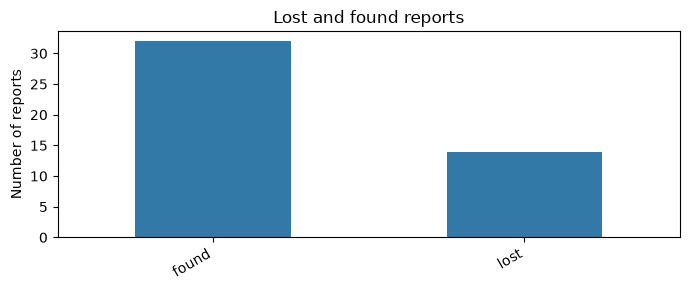

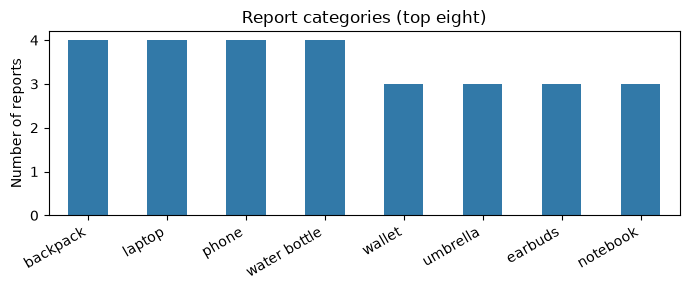

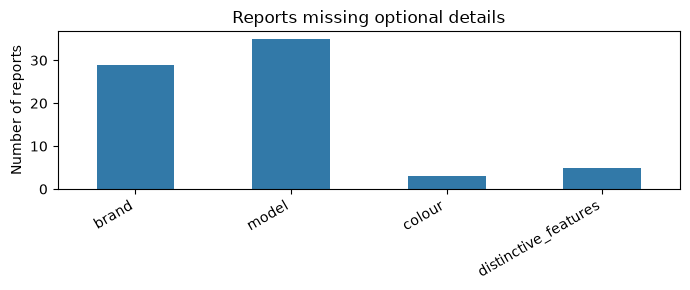

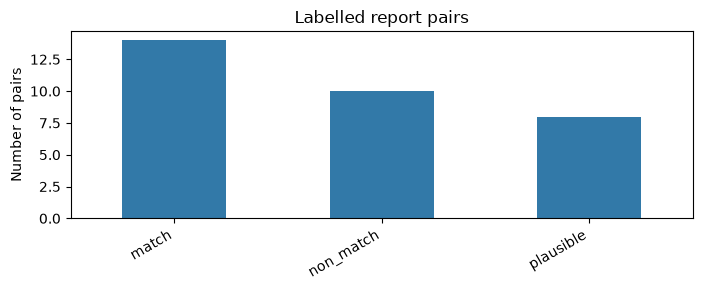

Saved four figures in C:\Users\HP\Documents\ChatGPT\Lost and Found system\SemProject_MLEngine\results\figures


In [5]:
figure_dir = ROOT / "results/figures"
figure_dir.mkdir(parents=True, exist_ok=True)
plots = [
    ("Lost and found reports", report_counts, "report_types.png", "Number of reports"),
    ("Report categories (top eight)", category_counts.head(8), "categories.png", "Number of reports"),
    ("Reports missing optional details", missing_counts, "missing_fields.png", "Number of reports"),
    ("Labelled report pairs", label_counts, "pair_labels.png", "Number of pairs"),
]
for title, counts, filename, ylabel in plots:
    ax = counts.plot.bar(title=title, figsize=(7, 3), color="#3279a8")
    ax.set_xlabel("")
    ax.set_ylabel(ylabel)
    plt.xticks(rotation=30, ha="right")
    plt.tight_layout()
    plt.savefig(figure_dir / filename, dpi=150)
    plt.show()
    plt.close()
print("Saved four figures in", figure_dir)

## 5. Turn each report pair into numbers

One row in the modelling table is **one lost report compared with one found report**. The features measure shared description words, shared distinctive details, shared location words, matching or conflicting item attributes, and time difference. For text overlap we use Jaccard similarity: shared unique words divided by all unique words in the two descriptions. Missing attributes create neither a match nor a conflict. See `matching_system/feature_builder.py` for the short function that calculates each feature.

The original three-way label is retained beside the numeric target. `match=1`; `non_match=0`; `plausible=0` is an explicit, uncertain assumption. This is **classification**, and Logistic Regression learns the feature weights from labelled examples.

In [6]:
pair_summary = build()
table = pd.read_csv(ROOT / "data/processed/modelling_pairs.csv")
print("Pair counts:", pair_summary["labels"])
print("Numeric features:", ", ".join(FEATURE_NAMES))
print("Modelling table example:")
print(table[["lost_report_id", "found_report_id", "original_label", "description_similarity", "colour_match", "colour_conflict", "time_difference_hours", "target"]].head(5).round(2).to_string(index=False))

Pair counts: {'match': 14, 'plausible': 8, 'non_match': 10}
Numeric features: description_similarity, category_match, category_conflict, colour_match, colour_conflict, brand_match, brand_conflict, model_match, model_conflict, material_match, material_conflict, distinctive_feature_similarity, location_similarity, time_difference_hours
Modelling table example:
lost_report_id found_report_id original_label  description_similarity  colour_match  colour_conflict  time_difference_hours  target
      lost-001       found-001          match                    0.55             1                0                   0.67       1
      lost-001       found-002      plausible                    0.15             1                0                   1.83       0
      lost-001       found-003      non_match                    0.08             0                1                   0.67       0
      lost-002       found-004          match                    0.45             1                0           

## 6. Split, train, and validate the model

We put all candidate pairs for a lost report in the **same** group. The fixed seed gives 24 development pairs from 10 lost reports and 8 held-out test pairs from 4 different lost reports. This avoids showing the model the same lost description during both training and testing. Within development, grouped cross-validation gives a more useful check than training accuracy.

Logistic Regression learns a weight for each feature, combines the weighted values, and converts the result into a probability.

`X` holds numeric pair features; `y` holds the known 0/1 labels. `StandardScaler` is fitted inside the classifier for each training fold, so validation data does not influence scaling. The next cell shows the key training action directly; the following cell runs the same fit and grouped checks to save the results.

In [7]:
manifest = split()["splits"]
development = table[table.lost_report_id.isin(manifest["development"]["lost_ids"])].copy()
held_out = table[table.lost_report_id.isin(manifest["test"]["lost_ids"])].copy()
X_train = development[list(FEATURE_NAMES)]
y_train = development.target
X_test = held_out[list(FEATURE_NAMES)]

model = new_classifier()
model.fit(X_train, y_train)
direct_probabilities = model.predict_proba(X_test)[:, 1]
print(f"Training: {len(X_train)} pairs from {development.lost_report_id.nunique()} lost reports")
print(f"Held-out test: {len(X_test)} pairs from {held_out.lost_report_id.nunique()} different lost reports")
print("First three match probabilities:", np.round(direct_probabilities[:3], 3))

Training: 24 pairs from 10 lost reports
Held-out test: 8 pairs from 4 different lost reports
First three match probabilities: [0.987 0.417 0.911]


In [8]:
results = run_experiment(ROOT / "data/processed/modelling_pairs.csv",
                         ROOT / "data/processed/campus_split.json",
                         ROOT / "results/ml")
predictions = pd.read_csv(ROOT / "results/ml/test_predictions.csv")
assert np.allclose(predictions.match_probability, direct_probabilities)

folds = pd.DataFrame(results["grouped_cv"])
print("Grouped cross-validation on development pairs:")
print(folds[["fold", "validation_lost_ids", "precision", "recall", "f1"]].round(2).to_string(index=False))
print()
print("Held-out test results:")
print(pd.Series({name: results["held_out_test"][name] for name in ("precision", "recall", "f1")}).round(3).to_string())
print("Confusion matrix (actual rows 0/1; predicted columns 0/1):")
matrix = np.array(results["held_out_test"]["confusion_matrix"])
print(matrix)
tn, fp, fn, tp = matrix.ravel()
print(f"True negatives: {tn}; false positives: {fp}; false negatives: {fn}; true positives: {tp}")

Grouped cross-validation on development pairs:
 fold  validation_lost_ids  precision  recall   f1
    1 [lost-001, lost-005]       1.00     1.0 1.00
    2 [lost-002, lost-006]       1.00     0.5 0.67
    3 [lost-003, lost-010]       0.67     1.0 0.80
    4 [lost-004, lost-011]       0.50     1.0 0.67
    5 [lost-012, lost-014]       0.67     1.0 0.80

Held-out test results:
precision    1.000
recall       0.750
f1           0.857
Confusion matrix (actual rows 0/1; predicted columns 0/1):
[[4 0]
 [1 3]]
True negatives: 4; false positives: 0; false negatives: 1; true positives: 3


## 7. Example predictions and errors

The probability can order *possible* found candidates for staff review. A `0.5` threshold turns it into a class prediction. Here are labelled examples, including an uncertain pair and a missed match. A false positive would waste staff effort; a false negative could hide a useful candidate. Neither outcome should bypass human ownership checks.

In [9]:
examples = pd.concat([
    predictions[predictions.original_label == "match"].head(1),
    predictions[predictions.original_label == "non_match"].head(1),
    predictions[predictions.original_label == "plausible"].head(1),
    predictions[(predictions.target == 1) & (predictions.predicted_class == 0)].head(1),
]).drop_duplicates(["lost_report_id", "found_report_id"])
descriptions = campus.set_index("report_id").description
for row in examples.itertuples():
    print()
    print(f"{row.lost_report_id} - {row.found_report_id} | label={row.original_label} | probability={row.match_probability:.3f} | predicted={row.predicted_class}")
    print(" Lost:", descriptions[row.lost_report_id])
    print("Found:", descriptions[row.found_report_id])

print()
print("Candidate order for one lost report:")
print(predictions[predictions.lost_report_id == "lost-007"][["found_report_id", "match_probability", "predicted_class"]].sort_values("match_probability", ascending=False).round(3).to_string(index=False))


lost-007 - found-017 | label=match | probability=0.987 | predicted=1
 Lost: White earbud case, left airpod missing, initials MK written inside
Found: White AirPods case with only right earbud and MK initials

lost-009 - found-022 | label=non_match | probability=0.110 | predicted=0
 Lost: Keys on blue lanyard with small bottle opener keychain
Found: Keys with red lanyard

lost-007 - found-018 | label=plausible | probability=0.417 | predicted=0
 Lost: White earbud case, left airpod missing, initials MK written inside
Found: White wireless earbuds case

lost-009 - found-021 | label=match | probability=0.445 | predicted=0
 Lost: Keys on blue lanyard with small bottle opener keychain
Found: Set of keys with blue neck strap and bottle opener

Candidate order for one lost report:
found_report_id  match_probability  predicted_class
      found-017              0.987                1
      found-018              0.417                0


## 8. Interpret the result and plan further validation

On this fixed eight-pair synthetic test, the saved result reports **precision, recall, F1, and a confusion matrix**. These numbers are a prototype check, not an estimate of real campus accuracy. There is at least one missed labelled match; inspect the example above rather than claiming the model always succeeds. Excluding the uncertain `plausible` labels changes the evaluation and leaves an even smaller sample; `results/ml/validation_metrics.json` records that sensitivity check.

Next we should have people independently review pair labels, collect consented campus reports, keep reports for the same physical item in one split, and compare Logistic Regression with a simple tree or support-vector model under the **same** split and metrics. That comparison is a future validation plan, not a measured result here. Images are also future work because we have no verified same-item photo pairs. The Android app does not currently use this trained classifier.

**Human decision:** this model suggests reports worth inspecting. Authorised staff must verify private ownership evidence before returning an item.